# 02. Исследование и подготовка данных
## Датасеты изображений · вторая неделя

**Автор / команда:** Сипко Максим Юрьевич, Мурашов Никита Александрович, группа КМБО-23-24  
**Название проекта:** Система распознавания эмоций покупателей в торговых точках  
**Датасет:** FER-2013 (Kaggle, `msambare/fer2013`)

Изучаем изображения лиц и готовим данные для разработки и проверки модели. Обучение модели в эту работу не входит.

## 1. Источник и состав данных

**Задача проекта:** классификация изображения лица по эмоции (7 классов). Один пример — одно изображение лица. Далее эмоции группируются в положительные, нейтральные и отрицательные для расчёта индекса удовлетворённости покупателей.

**Источник:** [FER-2013 на Kaggle](https://www.kaggle.com/datasets/msambare/fer2013) — копия набора из соревнования ICML 2013 *Challenges in Representation Learning* (Goodfellow I. J. et al., [arXiv:1307.0414](https://arxiv.org/abs/1307.0414)). Условия использования указаны на странице набора; данные используются только в учебных целях.

**Состав и разметка:** изображения лежат в папках `train/` и `test/`, внутри — по одной папке на каждую эмоцию (`angry`, `disgust`, `fear`, `happy`, `neutral`, `sad`, `surprise`). Метка берётся из имени папки. По описанию набора: 28 709 изображений в train и 7 178 в test (всего 35 887), одноканальные изображения 48×48 пикселей в оттенках серого. В исходном `fer2013.csv` тест состоял из двух частей (PublicTest и PrivateTest по 3 589 изображений); в версии Kaggle они объединены в одну папку `test`.

**Связанные примеры и ограничения:** в наборе нет ID людей, поэтому разделение по людям невозможно, а один и тот же человек может встречаться в нескольких частях. Проверяемые связи — точные копии изображений. Разметка выполнена автоматически и вручную, в ней известны ошибки: часть изображений не содержит лица, часть подписана неверно.

In [1]:
from pathlib import Path
import hashlib
import json
from concurrent.futures import ThreadPoolExecutor
from inspect import getsource

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

EMOTIONS = ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
EMOTION_RU = {'angry': 'злость', 'disgust': 'отвращение', 'fear': 'страх', 'happy': 'радость',
              'neutral': 'нейтральное', 'sad': 'грусть', 'surprise': 'удивление'}
EMOTION_GROUP = {'happy': 'положительная', 'neutral': 'нейтральная', 'surprise': 'нейтральная',
                 'angry': 'отрицательная', 'disgust': 'отрицательная', 'fear': 'отрицательная', 'sad': 'отрицательная'}


def find_data_root():
    for base in [Path('/kaggle/input'), Path('.')]:
        if not base.exists():
            continue
        for train_dir in base.rglob('train'):
            if train_dir.is_dir() and (train_dir / 'happy').is_dir() and (train_dir.parent / 'test').is_dir():
                return train_dir.parent
    raise FileNotFoundError('Не найден FER-2013. На Kaggle добавьте набор msambare/fer2013 через Add Input '
                            'или укажите путь вручную в переменной DATA_ROOT.')

### Загрузка

Читаем структуру папок и собираем таблицу: одна строка — одно изображение. Храним ID, путь, официальную часть (`train` или `test`), название эмоции и числовую метку. Сами изображения в память целиком не загружаем.

**Способ загрузки:** данные берутся из каталога Kaggle (`/kaggle/input/...`). Метка определяется по имени папки эмоции, числовой код — по порядку в списке `EMOTIONS`. Если запускаете не на Kaggle, скачайте набор и укажите путь в `DATA_ROOT`.

In [2]:
DATA_ROOT = find_data_root()
print('Данные:', DATA_ROOT)

records = []
for split in ['train', 'test']:
    for label_id, emotion in enumerate(EMOTIONS):
        folder = DATA_ROOT / split / emotion
        assert folder.is_dir(), f'Нет папки {folder}'
        for image_path in sorted(folder.iterdir()):
            if image_path.suffix.lower() in {'.jpg', '.jpeg', '.png'}:
                records.append({
                    'image_id': f'{split}/{emotion}/{image_path.name}',
                    'path': str(image_path),
                    'split_official': split,
                    'emotion': emotion,
                    'label': label_id
                })

df = pd.DataFrame(records)
display(df.head())

Данные: /kaggle/input/datasets/msambare/fer2013


,image_id,path,split_official,emotion,label
0,train/angry/Training_10118481.jpg,/kaggle/input/datasets/msambare/fer2013/train/...,train,angry,0
1,train/angry/Training_10120469.jpg,/kaggle/input/datasets/msambare/fer2013/train/...,train,angry,0
2,train/angry/Training_10131352.jpg,/kaggle/input/datasets/msambare/fer2013/train/...,train,angry,0
3,train/angry/Training_10161559.jpg,/kaggle/input/datasets/msambare/fer2013/train/...,train,angry,0
4,train/angry/Training_1021836.jpg,/kaggle/input/datasets/msambare/fer2013/train/...,train,angry,0


In [3]:
print('Размер таблицы:', df.shape)
df.info()
display(pd.crosstab(df['split_official'], df['emotion'], margins=True))

Размер таблицы: (35887, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35887 entries, 0 to 35886
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   image_id        35887 non-null  object
 1   path            35887 non-null  object
 2   split_official  35887 non-null  object
 3   emotion         35887 non-null  object
 4   label           35887 non-null  int64 
dtypes: int64(1), object(4)
memory usage: 1.4+ MB


emotion,angry,disgust,fear,happy,neutral,sad,surprise,All
split_official,,,,,,,,
test,958,111,1024,1774,1233,1247,831,7178
train,3995,436,4097,7215,4965,4830,3171,28709
All,4953,547,5121,8989,6198,6077,4002,35887


## 2. Проверка качества данных

### 2.1. Пропуски и читаемость файлов

Проверяем обязательные поля, существование и полное чтение файлов. При чтении записываем размеры, режим цвета, диапазон пикселей, среднюю яркость и контраст (стандартное отклонение). Режим цвета не меняем до проверки, чтобы не скрыть различия каналов.

Ноль в пикселе — это чёрный цвет, а не пропуск.

In [4]:
required_columns = ['image_id', 'path', 'split_official', 'emotion', 'label']
display(df[required_columns].isna().sum().to_frame('missing'))

pixel_cache = {}


def read_image(image_path):
    info = {'width': None, 'height': None, 'mode': None,
            'pixel_min': None, 'pixel_max': None, 'mean': None, 'std': None, 'read_error': None}
    pixels = None
    try:
        with Image.open(image_path) as image:
            image.load()
            pixels = np.asarray(image)
            info['width'] = image.width
            info['height'] = image.height
            info['mode'] = image.mode
            info['pixel_min'] = int(pixels.min())
            info['pixel_max'] = int(pixels.max())
            info['mean'] = float(pixels.mean())
            info['std'] = float(pixels.std())
    except Exception as error:
        info['read_error'] = str(error)
    return image_path, pixels, info


with ThreadPoolExecutor(max_workers=16) as executor:
    results = list(executor.map(read_image, df['path']))

image_records = []
for image_path, pixels, info in results:
    if pixels is not None:
        pixel_cache[image_path] = pixels
    image_records.append(info)

image_info = pd.DataFrame(image_records)
for column in image_info.columns:
    df[column] = image_info[column].tolist()

print('Ошибок чтения:', int(df['read_error'].notna().sum()))
display(df[['width', 'height', 'pixel_min', 'pixel_max', 'mean', 'std']].describe())
display(df['mode'].value_counts().to_frame('count'))
display(df.groupby(['width', 'height']).size().to_frame('count'))

,missing
image_id,0
path,0
split_official,0
emotion,0
label,0


Ошибок чтения: 0


,width,height,pixel_min,pixel_max,mean,std
count,35887.0,35887.0,35887.000000,35887.000000,35887.000000,35887.000000
mean,48.0,48.0,7.725193,236.742191,129.384900,54.084109
std,0.0,0.0,12.950338,24.676312,33.517589,13.650491
min,48.0,48.0,0.000000,0.000000,0.000000,0.000000
25%,48.0,48.0,0.000000,227.000000,106.777778,44.546586
50%,48.0,48.0,1.000000,247.000000,129.537760,53.668716
75%,48.0,48.0,11.000000,255.000000,152.635851,63.163924
max,48.0,48.0,205.000000,255.000000,247.953993,113.933127


,count
mode,
L,35887


,,count
width,height,
48,48,35887


**Что обнаружено:** пропусков в обязательных полях нет, нечитаемых файлов нет (0 из 35 887). Все изображения имеют размер 48×48 и режим `L` (один канал); значения пикселей лежат в диапазоне 0–255, средняя яркость по набору около 129.

**Решение:** исключать нечитаемые файлы не требуется (их нет); одноканальный формат 48×48 сохраняем — перевод в RGB или увеличение размера не добавит информации.

### 2.2. Корректность разметки

Проверяем допустимые классы и соответствие меток папкам. Часть разметки обязательно просматриваем вместе с изображениями — это показано ниже.

Неизвестных меток: 0
Лишних папок классов: []


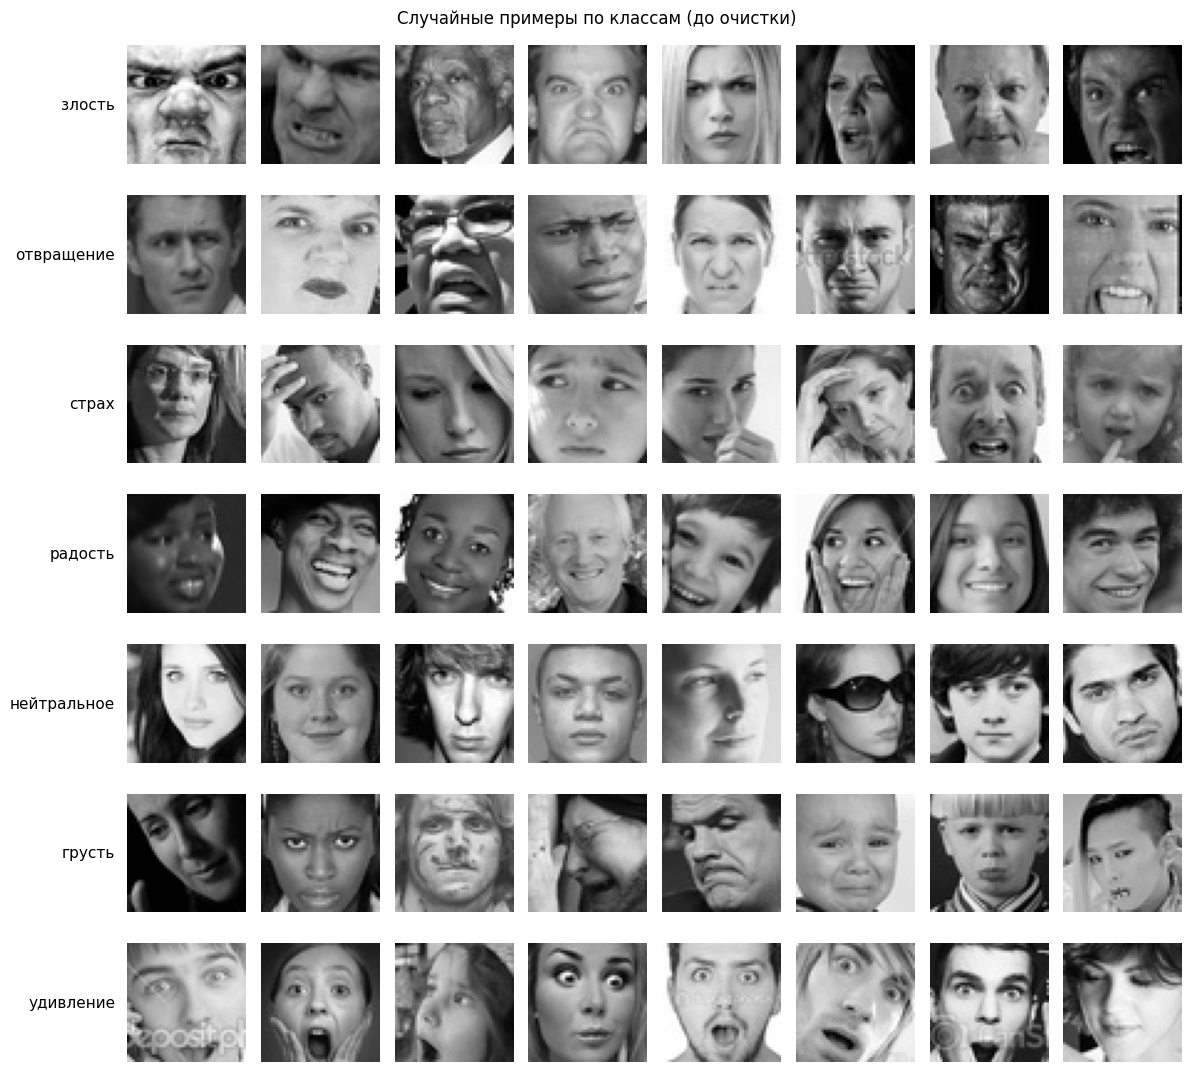

In [5]:
allowed_labels = list(range(len(EMOTIONS)))
bad_labels = df[~df['label'].isin(allowed_labels)]
unknown_dirs = [d.name for part in ['train', 'test'] for d in (DATA_ROOT / part).iterdir()
                if d.is_dir() and d.name not in EMOTIONS]

print('Неизвестных меток:', len(bad_labels))
print('Лишних папок классов:', unknown_dirs)
assert df['image_id'].is_unique
assert len(bad_labels) == 0
assert (df['emotion'] == df['label'].map(dict(enumerate(EMOTIONS)))).all()

fig, axes = plt.subplots(len(EMOTIONS), 8, figsize=(12, 11))
for row, emotion in enumerate(EMOTIONS):
    sample = df[df['emotion'] == emotion].sample(8, random_state=RANDOM_STATE)
    for col, image_path in enumerate(sample['path']):
        with Image.open(image_path) as image:
            axes[row, col].imshow(image, cmap='gray', vmin=0, vmax=255)
        axes[row, col].axis('off')
    axes[row, 0].text(-0.1, 0.5, EMOTION_RU[emotion], transform=axes[row, 0].transAxes,
                      ha='right', va='center', fontsize=11)
plt.suptitle('Случайные примеры по классам (до очистки)')
plt.tight_layout()
plt.show()

**Что обнаружено:** метки соответствуют папкам, неизвестных классов нет. По просмотру: изображения — крупные планы лиц в оттенках серого; различаются возраст, пол, ракурс, освещение и качество. На части примеров заметны водяные знаки стоковых сайтов (например, в строках «отвращение» и «удивление»), лица закрыты рукой или тёмными очками. Часть меток выглядит спорной: например, среди «грусти» встречается лицо, похожее на злое, а среди «страха» — похожие на грустные или нейтральные; близкие по выражению классы действительно легко перепутать.

**Решение:** вручную разметку не исправляем: проверить все 35 тысяч изображений невозможно. Шум разметки учитываем при интерпретации метрик (по литературе, точность человека на этом наборе около 65 %).

### 2.3. Дубликаты и связанные примеры

Проверяем повторяющиеся ID и пути, а также точные копии изображений. Считаем хеш **значений пикселей** (а не байтов файла), чтобы не зависеть от способа кодирования JPEG. Дополнительно считаем простой хеш разности соседних пикселей (dHash) для поиска визуально почти одинаковых изображений — он только информирует и для удаления не используется.

Важная проверка для эмоций: одна и та же картинка с **разными метками** означает ненадёжную разметку.

Повторяющихся ID: 0
Повторяющихся путей: 0
Изображений, имеющих точную копию: 3369
Групп точных копий: 1516
Лишних копий (можно удалить): 1853
Групп с РАЗНЫМИ метками: 57
Групп, попавших и в train, и в test: 531
Изображений с визуально почти одинаковым dHash (без точных копий): 187


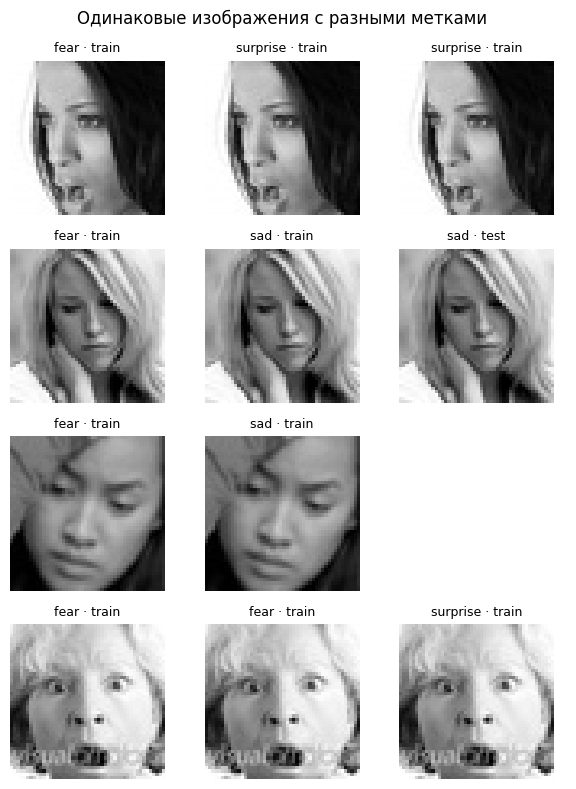

In [6]:
print('Повторяющихся ID:', df['image_id'].duplicated().sum())
print('Повторяющихся путей:', df['path'].duplicated().sum())


def dhash(pixels, size=8):
    small = Image.fromarray(pixels).resize((size + 1, size), Image.LANCZOS)
    arr = np.asarray(small, dtype=np.int16)
    return ''.join('1' if bit else '0' for bit in (arr[:, 1:] > arr[:, :-1]).flatten())


pixel_hashes = []
dhashes = []

for image_path in df['path']:
    pixels = pixel_cache.get(image_path)
    if pixels is None:
        pixel_hashes.append(None)
        dhashes.append(None)
    else:
        pixel_hashes.append(hashlib.sha256(pixels.tobytes()).hexdigest())
        dhashes.append(dhash(pixels))

df['pixel_hash'] = pixel_hashes
df['dhash'] = dhashes

readable = df['pixel_hash'].notna()
dup_all = df[readable & df['pixel_hash'].duplicated(keep=False)]
groups = dup_all.groupby('pixel_hash')

print('Изображений, имеющих точную копию:', len(dup_all))
print('Групп точных копий:', groups.ngroups)
print('Лишних копий (можно удалить):', int((readable & df['pixel_hash'].duplicated()).sum()))
print('Групп с РАЗНЫМИ метками:', int((groups['label'].nunique() > 1).sum()))
print('Групп, попавших и в train, и в test:', int((groups['split_official'].nunique() > 1).sum()))

near = readable & df['dhash'].duplicated(keep=False) & ~df['pixel_hash'].duplicated(keep=False)
print('Изображений с визуально почти одинаковым dHash (без точных копий):', int(near.sum()))

conflict_hashes = groups['label'].nunique()
conflict_hashes = conflict_hashes[conflict_hashes > 1].index[:4]
if len(conflict_hashes) > 0:
    fig, axes = plt.subplots(len(conflict_hashes), 3, figsize=(6, 2 * len(conflict_hashes)), squeeze=False)
    for row, hash_value in enumerate(conflict_hashes):
        members = df[df['pixel_hash'] == hash_value].head(3)
        for col in range(3):
            axes[row, col].axis('off')
            if col < len(members):
                item = members.iloc[col]
                with Image.open(item['path']) as image:
                    axes[row, col].imshow(image, cmap='gray', vmin=0, vmax=255)
                axes[row, col].set_title(f"{item['emotion']} · {item['split_official']}", fontsize=9)
    plt.suptitle('Одинаковые изображения с разными метками')
    plt.tight_layout()
    plt.show()

**Что обнаружено:** 3 369 изображений имеют точную копию; они образуют 1 516 групп, то есть 1 853 копии лишние. В 57 группах одинаковое изображение имеет разные метки (на графике видно, что одно и то же лицо подписано как «страх», «удивление» или «грусть»). 531 группа точных копий попала одновременно в train и test, то есть при простом использовании набора часть тестовых изображений уже есть в обучающей выборке. Ещё 187 изображений визуально почти одинаковы по dHash, но не совпадают точно. ID людей в наборе нет, поэтому связи между разными фотографиями одного человека проверить нельзя.

**Решение:** (1) изображения, у которых копия имеет другую метку, считаем ненадёжными и удаляем из обучающей части; (2) изображения train, у которых есть копия в официальном test, удаляем из train, чтобы не было утечки; (3) оставшиеся копии с одинаковой меткой внутри train сводим к одному экземпляру. Официальный test не меняем, чтобы результаты были сопоставимы с литературой. Почти одинаковые по dHash изображения не удаляем (возможны ложные срабатывания), но фиксируем как ограничение.

### 2.4. Ошибки и аномалии

Проверяем подозрительные размеры, диапазоны и качество. Тёмное или светлое изображение само по себе не ошибка. Но **однотонное изображение** (контраст почти равен нулю) не содержит лица и не несёт информации об эмоции.

Неожиданных размеров: 0
Неожиданных режимов цвета: 0
Ошибок диапазона: 0
Практически однотонных изображений (std < 1): 13
  из них в train: 12 , в test: 1


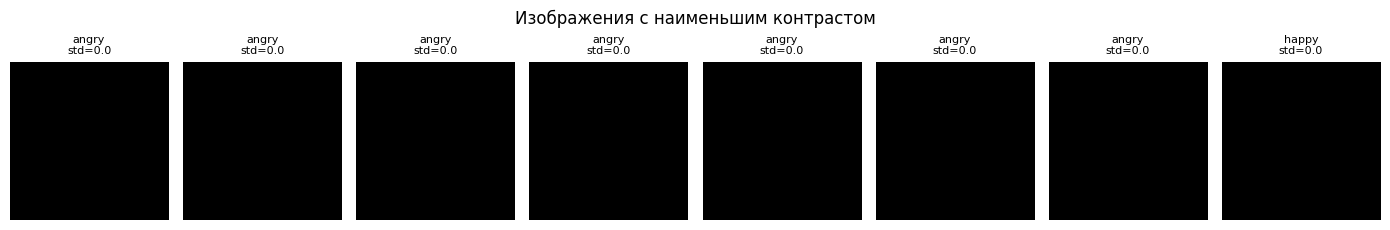

In [7]:
bad_size = (df['width'] != 48) | (df['height'] != 48)
bad_mode = df['mode'] != 'L'
bad_range = (df['pixel_min'] < 0) | (df['pixel_max'] > 255)
flat = df['std'] < 1.0

print('Неожиданных размеров:', int(bad_size.sum()))
print('Неожиданных режимов цвета:', int(bad_mode.sum()))
print('Ошибок диапазона:', int(bad_range.sum()))
print('Практически однотонных изображений (std < 1):', int(flat.sum()))
print('  из них в train:', int((flat & (df['split_official'] == 'train')).sum()),
      ', в test:', int((flat & (df['split_official'] == 'test')).sum()))

lowest = df[df['std'].notna()].nsmallest(8, 'std')
fig, axes = plt.subplots(1, 8, figsize=(14, 2.4))
for ax, (_, item) in zip(axes, lowest.iterrows()):
    with Image.open(item['path']) as image:
        ax.imshow(image, cmap='gray', vmin=0, vmax=255)
    ax.set_title(f"{item['emotion']}\nstd={item['std']:.1f}", fontsize=8)
    ax.axis('off')
plt.suptitle('Изображения с наименьшим контрастом')
plt.tight_layout()
plt.show()

**Вывод о качестве:** размеры и режим цвета единые (48×48, `L`), неожиданных значений и ошибок диапазона нет. Найдено 13 практически однотонных изображений (12 в train, 1 в test). Восемь наименее контрастных кадров на графике — полностью чёрные изображения (семь из класса «злость», одно из класса «радость»), лица на них нет. Сложные, тёмные или частично закрытые лица не удаляем: магазинная съёмка тоже будет неидеальной.

### 2.5. Баланс классов

Считаем число и долю изображений каждого класса отдельно в официальных train и test.

In [8]:
class_counts = pd.crosstab(df['emotion'], df['split_official']).reindex(EMOTIONS)
class_shares = (class_counts / class_counts.sum() * 100).round(2)
display(pd.concat({'count': class_counts, 'percent': class_shares}, axis=1))

train_counts_raw = class_counts['train']
print('Отношение самого частого класса к самому редкому (train):',
      round(train_counts_raw.max() / train_counts_raw.min(), 1))
print('Доля по группам (train, %):')
print((df[df['split_official'] == 'train']['emotion'].map(EMOTION_GROUP).value_counts(normalize=True) * 100).round(1))

count       percent       
split_official  test train    test  train
emotion                                  
angry            958  3995   13.35  13.92
disgust          111   436    1.55   1.52
fear            1024  4097   14.27  14.27
happy           1774  7215   24.71  25.13
neutral         1233  4965   17.18  17.29
sad             1247  4830   17.37  16.82
surprise         831  3171   11.58  11.05

Отношение самого частого класса к самому редкому (train): 16.5
Доля по группам (train, %):
emotion
отрицательная    46.5
нейтральная      28.3
положительная    25.1
Name: proportion, dtype: float64


**Вывод о разметке:** классы сильно несбалансированы. По описанию набора, в train «радость» — 7 215 изображений, а «отвращение» — только 436 (около 1,5 %), в test — 1 774 и 111. Числа подтверждены таблицей выше. Отношение самого частого класса к самому редкому в train — 16,5; по укрупнённым группам отрицательные эмоции составляют 46,5 %, нейтральные — 28,3 %, положительная — 25,1 %. Редкие классы будут давать нестабильные метрики, поэтому основной метрикой выбрана macro-F1, а при обучении планируем взвешивание классов.

### Решения по очистке

| Проблема | Сколько примеров затронуто | Действие | Обоснование |
|---|---|---|---|
| Нечитаемые файлы | 0 | Удалить | Нельзя использовать для обучения |
| Однотонные изображения (train) | 12 | Удалить | Нет лица, нет информации об эмоции |
| Копии с разными метками | 116 | Удалить из train | Метка ненадёжна |
| Копии train, лежащие в test | 649 | Удалить из train | Исключаем утечку в тест |
| Точные копии с одной меткой в train | 1 021 | Оставить один экземпляр | Исключаем повторы и утечку между train и validation |
| Дисбаланс классов | — | Не менять данные | Учтём весами классов и метрикой macro-F1; искусственных копий не создаём |

Всего удалено 1 798 изображений (35 887 → 34 089). Очистка выполняется до разделения. Test остаётся официальным и не меняется (кроме нечитаемых файлов, если они есть). Аугментации заранее не создаём.

In [9]:
df_clean = df.copy()
cleaning_log = []


def drop_rows(mask, problem):
    global df_clean
    mask = mask.reindex(df_clean.index, fill_value=False)
    cleaning_log.append({'problem': problem, 'removed': int(mask.sum())})
    df_clean = df_clean[~mask]


is_train = lambda: df_clean['split_official'] == 'train'

drop_rows(df_clean['read_error'].notna(), 'Нечитаемые файлы')

drop_rows(is_train() & (df_clean['std'] < 1.0), 'Однотонные изображения (train)')

labels_per_hash = df_clean.groupby('pixel_hash')['label'].nunique()
conflict_hashes = set(labels_per_hash[labels_per_hash > 1].index)
drop_rows(is_train() & df_clean['pixel_hash'].isin(conflict_hashes), 'Копии с разными метками (из train)')

test_hashes = set(df_clean.loc[df_clean['split_official'] == 'test', 'pixel_hash'])
drop_rows(is_train() & df_clean['pixel_hash'].isin(test_hashes), 'Копии train, лежащие в test')

train_dups = is_train() & df_clean.duplicated(subset=['pixel_hash'], keep='first')
drop_rows(train_dups, 'Лишние точные копии внутри train')

df_clean = df_clean.reset_index(drop=True)
display(pd.DataFrame(cleaning_log))

print('До очистки:', len(df))
print('После очистки:', len(df_clean))
assert df_clean['read_error'].isna().all()
assert df_clean['label'].notna().all()
train_part = df_clean[df_clean['split_official'] == 'train']
assert train_part['pixel_hash'].is_unique
assert len(set(train_part['pixel_hash']) & set(df_clean.loc[df_clean['split_official'] == 'test', 'pixel_hash'])) == 0

,problem,removed
0,Нечитаемые файлы,0
1,Однотонные изображения (train),12
2,Копии с разными метками (из train),116
3,"Копии train, лежащие в test",649
4,Лишние точные копии внутри train,1021


До очистки: 35887
После очистки: 34089


## 3. Разделение данных

Разделяем данные перед подробным исследованием и настройкой обработки.

- **Train** — исследование, обучение обработки и модели.
- **Validation** — выбор настроек и сравнение вариантов модели.
- **Test** — итоговая проверка выбранной модели.

**Способ и доли:** у FER-2013 есть официальное разделение, поэтому **test сохраняем официальным** (папка `test`). Validation выделяем из официального train: 15 % случайно со стратификацией по метке (`train_test_split`, `random_state = 42`). Стратификация нужна, чтобы редкий класс «отвращение» попал в каждую часть в той же доле. После очистки (34 089 изображений) получается примерно 67 % / 12 % / 21 %.

**Защита от утечки и ограничения:** все точные копии изображений удалены из train, поэтому одна и та же картинка не может оказаться одновременно в train, validation и test (проверка по хешу пикселей в ячейке ниже). Остаются неустранимые ограничения: в наборе нет ID людей, поэтому разные фотографии одного человека могут попасть в разные части; визуально почти одинаковые изображения нельзя полностью исключить. Аугментации до разделения не создавались.

In [10]:
pool_df = df_clean[df_clean['split_official'] == 'train']
test_df = df_clean[df_clean['split_official'] == 'test'].reset_index(drop=True)

train_df, val_df = train_test_split(
    pool_df,
    test_size=0.15,
    random_state=RANDOM_STATE,
    stratify=pool_df['label']
)
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

print('Train:', len(train_df))
print('Validation:', len(val_df))
print('Test:', len(test_df))

Train: 22874
Validation: 4037
Test: 7178


In [11]:
parts = {'train': train_df, 'validation': val_df, 'test': test_df}
pairs = [('train', 'validation'), ('train', 'test'), ('validation', 'test')]

for left_name, right_name in pairs:
    left = parts[left_name]
    right = parts[right_name]

    for column in ['image_id', 'path', 'pixel_hash']:
        common = set(left[column]).intersection(set(right[column]))
        assert len(common) == 0, f'Пересечение {column}: {left_name}, {right_name}'

    near_common = set(left['dhash']).intersection(set(right['dhash']))
    near_rows = int(right['dhash'].isin(near_common).sum())
    print(f'{left_name} / {right_name}: общих dHash — {len(near_common)} (строк во второй части: {near_rows})')

all_ids = set()
total_rows = 0
for part in parts.values():
    total_rows += len(part)
    all_ids.update(part['image_id'])
assert total_rows == len(df_clean)
assert all_ids == set(df_clean['image_id'])

balance = pd.DataFrame({name: part['emotion'].value_counts().reindex(EMOTIONS) for name, part in parts.items()})
for name, part in parts.items():
    balance[name + ' %'] = (balance[name] / balance[name].sum() * 100).round(2)
display(balance)
assert (balance[['train', 'validation', 'test']] > 0).all().all()
print('Проверки разбиения выполнены: пересечений ID, путей и точных копий нет.')

train / validation: общих dHash — 23 (строк во второй части: 23)
train / test: общих dHash — 36 (строк во второй части: 43)
validation / test: общих dHash — 11 (строк во второй части: 13)


,train,validation,test,train %,validation %,test %
emotion,,,,,,
angry,3210,566,958,14.03,14.02,13.35
disgust,298,52,111,1.30,1.29,1.55
fear,3227,570,1024,14.11,14.12,14.27
happy,5975,1055,1774,26.12,26.13,24.71
neutral,4098,723,1233,17.92,17.91,17.18
sad,3975,702,1247,17.38,17.39,17.37
surprise,2091,369,831,9.14,9.14,11.58


Проверки разбиения выполнены: пересечений ID, путей и точных копий нет.


**Результат:** train — 22 874, validation — 4 037, test — 7 178 изображений. Все 7 классов есть в каждой части, доли классов в train и validation почти совпадают (стратификация); доли в test отличаются, потому что test — официальная выборка (например, «удивление» — 11,6 % в test и 9,1 % в train). Пересечений ID, путей и точных копий между частями нет. Ограничения: нет ID людей; почти одинаковые изображения по dHash между частями есть: общих dHash между train и validation — 23, между train и test — 36, между validation и test — 11. Это единичные случаи (возможны ложные срабатывания), мы их не удаляем.

## 4. Визуализации и исследование

Используем только train. Графики подписаны, после каждого — наблюдение и вывод для подготовки данных.

### 4.1. Первый вопрос исследования

**Что хотите узнать:** как выглядят лица разных эмоций и насколько они различимы по внешнему виду?

**Почему выбран этот способ просмотра:** сетка примеров позволяет сравнить выражения, ракурс, освещение и качество изображения в одном классе. Это выборочная визуальная проверка, а не подтверждение всей разметки.

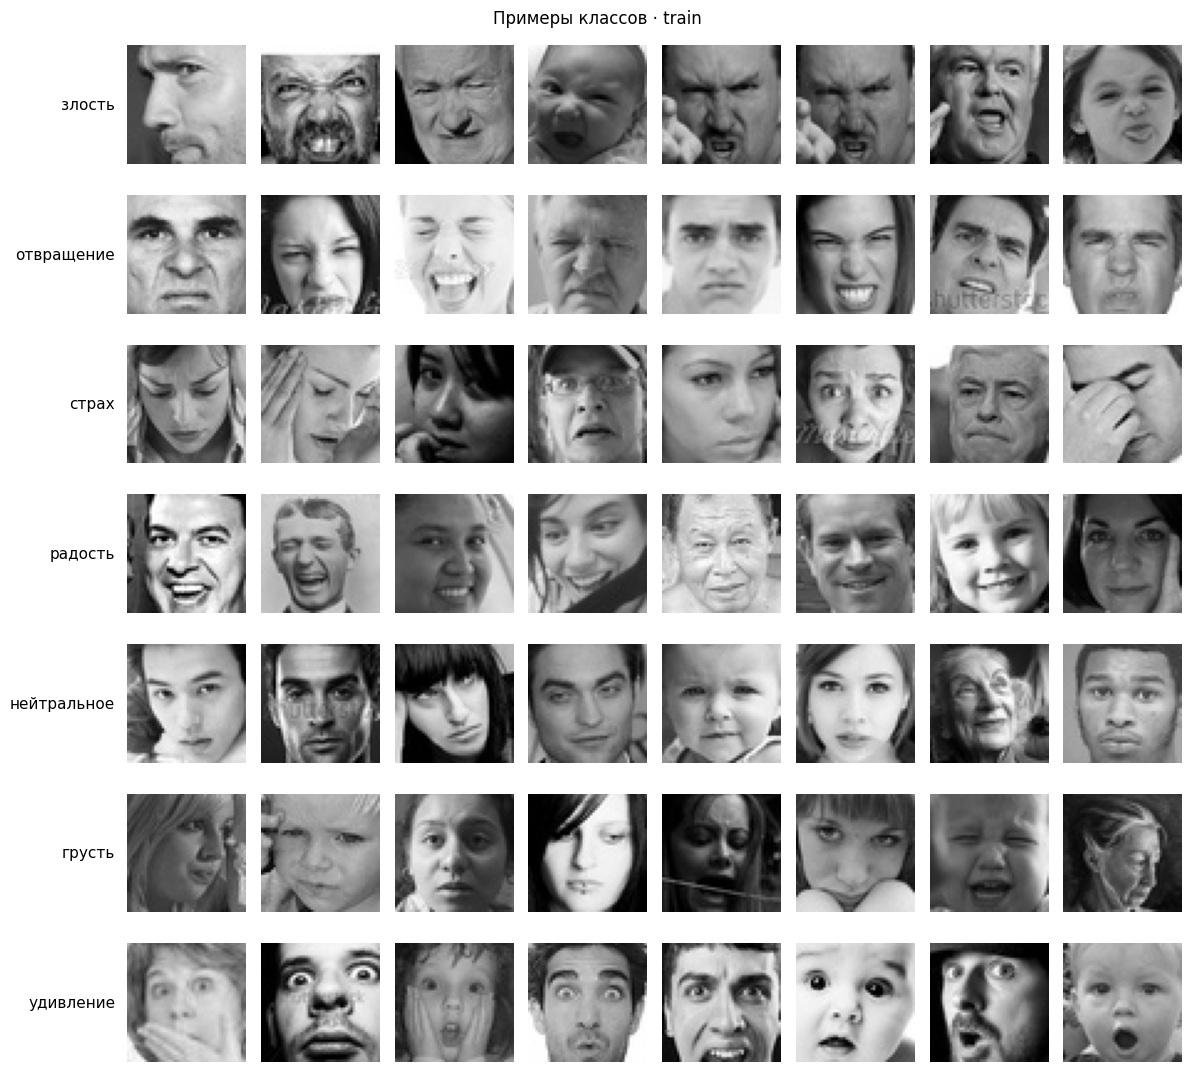

In [12]:
fig, axes = plt.subplots(len(EMOTIONS), 8, figsize=(12, 11))
for row, emotion in enumerate(EMOTIONS):
    sample = train_df[train_df['emotion'] == emotion].sample(8, random_state=RANDOM_STATE)
    for col, image_path in enumerate(sample['path']):
        with Image.open(image_path) as image:
            axes[row, col].imshow(image, cmap='gray', vmin=0, vmax=255)
        axes[row, col].axis('off')
    axes[row, 0].text(-0.1, 0.5, EMOTION_RU[emotion], transform=axes[row, 0].transAxes,
                      ha='right', va='center', fontsize=11)
plt.suptitle('Примеры классов · train')
plt.tight_layout()
plt.show()

**Наблюдение:** лица маленькие и серые, различаются ракурс, освещение, возраст и пол. Радость и удивление отличаются заметно (улыбка и широко открытый рот, поднятые брови), а страх, грусть, злость и отвращение визуально близки и частично перемешаны. Встречаются закрытые лица и водяные знаки.

**Вывод для подготовки данных:** сохраняем исходное разрешение 48×48 и один канал. В обучении будем использовать только аугментации, сохраняющие смысл эмоции: горизонтальное отражение, небольшой поворот и сдвиг. Сильные искажения могут менять выражение лица.

### 4.2. Второй вопрос исследования

**Что хотите узнать:** насколько несбалансированы классы и одинаково ли они распределены в train, validation и test?

**Почему выбран этот график:** столбчатая диаграмма показывает число изображений в train, а сравнение долей по частям — что разделение не исказило структуру классов.

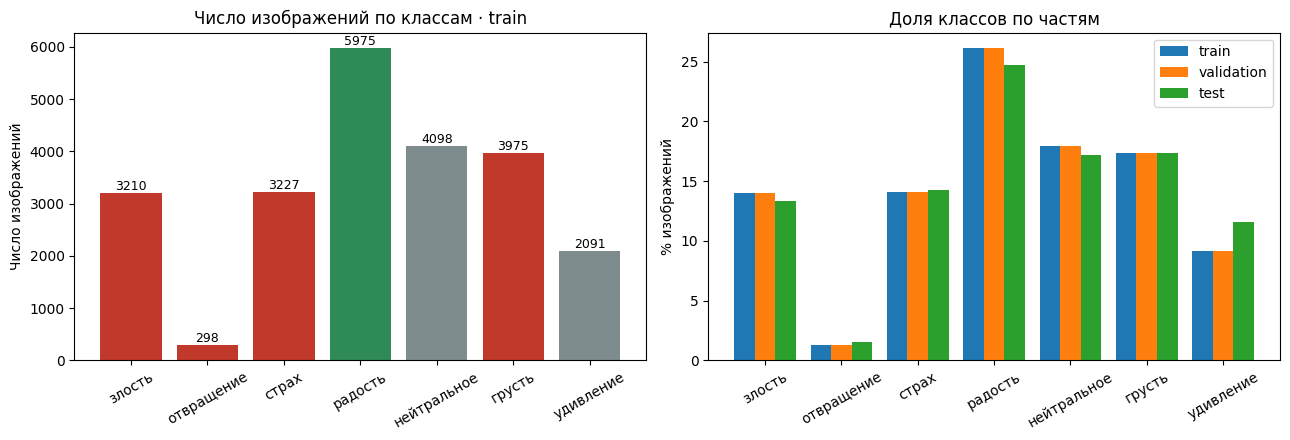

In [13]:
train_counts = train_df['emotion'].value_counts().reindex(EMOTIONS)
colors = ['#c0392b', '#c0392b', '#c0392b', '#2e8b57', '#7f8c8d', '#c0392b', '#7f8c8d']

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
bars = axes[0].bar([EMOTION_RU[e] for e in EMOTIONS], train_counts.values, color=colors)
for bar, value in zip(bars, train_counts.values):
    axes[0].text(bar.get_x() + bar.get_width() / 2, value, str(value), ha='center', va='bottom', fontsize=9)
axes[0].set(title='Число изображений по классам · train', ylabel='Число изображений')
axes[0].tick_params(axis='x', rotation=30)

width = 0.27
x = np.arange(len(EMOTIONS))
for shift, (name, part) in zip([-width, 0, width], parts.items()):
    shares = part['emotion'].value_counts(normalize=True).reindex(EMOTIONS) * 100
    axes[1].bar(x + shift, shares.values, width, label=name)
axes[1].set_xticks(x)
axes[1].set_xticklabels([EMOTION_RU[e] for e in EMOTIONS], rotation=30)
axes[1].set(title='Доля классов по частям', ylabel='% изображений')
axes[1].legend()
plt.tight_layout()
plt.show()

**Наблюдение:** класс «радость» самый частый (5 975 изображений, 26,1 % train), «отвращение» самый редкий (298 изображений, 1,3 % train после очистки); доли классов в train и validation практически совпадают, в test близки, заметнее всего отличается «удивление». Красным на левом графике отмечены отрицательные эмоции, зелёным — положительная, серым — нейтральные.

**Вывод для подготовки данных:** выравнивание классов копированием не выполняем. При обучении будем использовать веса классов, рассчитанные только по train, а качество оценивать по macro-F1 и recall по негативным эмоциям.

### 4.3. Особенности изображений

Размер и режим цвета у всех изображений одинаковы (проверено выше). Изучаем яркость и контраст изображений по классам и усреднённое лицо каждого класса: это помогает выбрать нормализацию и увидеть, не различаются ли классы условиями съёмки.

**Выбранные проверки и причины:** если средняя яркость или контраст сильно зависят от класса, модель может использовать условия съёмки вместо выражения лица.

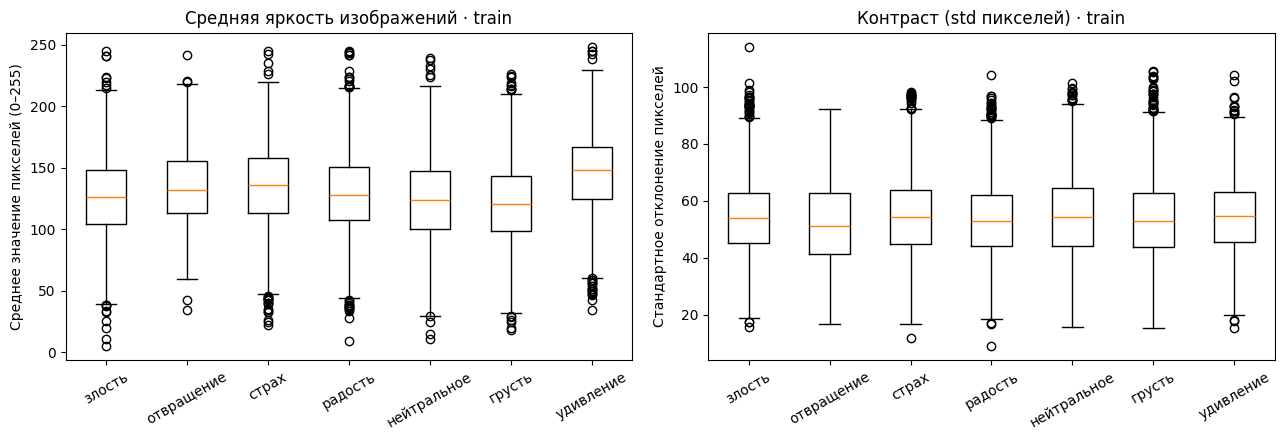

Медиана средней яркости (train): 128.6
Медиана контраста (train): 53.6


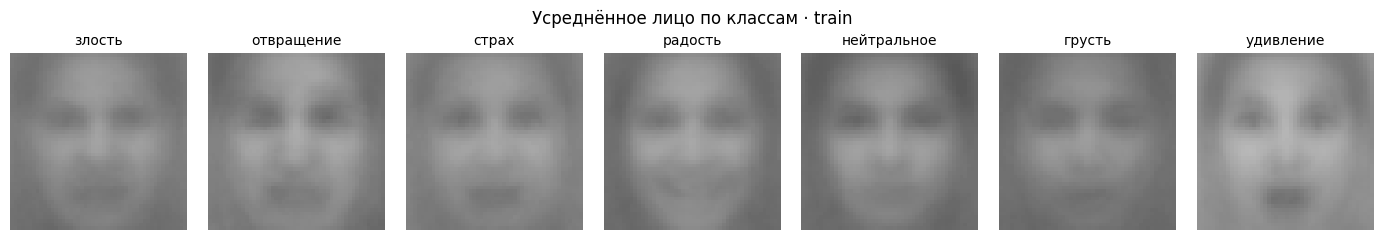

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
order = [EMOTION_RU[e] for e in EMOTIONS]
train_df = train_df.assign(emotion_ru=train_df['emotion'].map(EMOTION_RU))
axes[0].boxplot([train_df.loc[train_df['emotion_ru'] == n, 'mean'] for n in order])
axes[0].set_xticklabels(order)
axes[0].set(title='Средняя яркость изображений · train', ylabel='Среднее значение пикселей (0–255)')
axes[1].boxplot([train_df.loc[train_df['emotion_ru'] == n, 'std'] for n in order])
axes[1].set_xticklabels(order)
axes[1].set(title='Контраст (std пикселей) · train', ylabel='Стандартное отклонение пикселей')
for ax in axes:
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

print('Медиана средней яркости (train):', round(float(train_df['mean'].median()), 1))
print('Медиана контраста (train):', round(float(train_df['std'].median()), 1))

fig, axes = plt.subplots(1, len(EMOTIONS), figsize=(14, 2.4))
for ax, emotion in zip(axes, EMOTIONS):
    sample = train_df[train_df['emotion'] == emotion].head(500)
    stack = []
    for image_path in sample['path']:
        stack.append(pixel_cache[image_path].astype(np.float32))
    ax.imshow(np.mean(stack, axis=0), cmap='gray', vmin=0, vmax=255)
    ax.set_title(EMOTION_RU[emotion], fontsize=10)
    ax.axis('off')
plt.suptitle('Усреднённое лицо по классам · train')
plt.tight_layout()
plt.show()

**Вывод:** контраст по классам почти одинаков (медиана около 51–55). Яркость различается умеренно: у «удивления» медиана самая высокая (около 148), у «грусти» и «нейтрального» самая низкая (около 120–124), остальные классы лежат между ними. Это небольшая зависимость класса от условий съёмки, её стоит учесть при обучении (аугментация яркости и контраста). Усреднённые лица показывают, что лица в основном по центру кадра, глаза и рот находятся в одних и тех же местах; у «удивления» виден открытый рот, у «радости» — улыбка. Диапазон значений 0–255 подтверждён, нулевые значения — это тёмные области, а не пропуски. Поэтому достаточно фиксированной нормализации делением на 255; изменение размера не требуется.

## 5. Предобработка

**План обработки и обоснование:** изображения одноканальные 48×48, читаем значения в `float32` и делим на 255. Получаем массивы формы `(число изображений, 48, 48)` в диапазоне 0–1; ось канала добавляется на этапе обучения. Изменение размера не нужно — формат единый. Метки — целые числа 0–6. Веса классов рассчитываем **только по train** и сохраняем для обучения. Аугментации (отражение, поворот до ±10°, небольшой сдвиг) применяются только к train и **на лету во время обучения**, заранее копии не создаём. Правило нормализации фиксированное, обучаемых параметров у него нет, поэтому одна и та же функция применяется ко всем частям.

In [15]:
image_arrays = {}
label_arrays = {}

for name, part in parts.items():
    images = []

    for image_path in part['path']:
        images.append(pixel_cache[image_path].astype(np.float32))

    image_arrays[name] = np.stack(images)
    label_arrays[name] = part['label'].to_numpy(dtype=np.int64)

X_train = image_arrays['train']
X_val = image_arrays['validation']
X_test = image_arrays['test']
y_train = label_arrays['train']
y_val = label_arrays['validation']
y_test = label_arrays['test']

print('Исходные формы:', X_train.shape, X_val.shape, X_test.shape)

Исходные формы: (22874, 48, 48) (4037, 48, 48) (7178, 48, 48)


In [16]:
def normalize_images(images):
    return images.astype(np.float32) / 255.0


X_train_prepared = normalize_images(X_train)
X_val_prepared = normalize_images(X_val)
X_test_prepared = normalize_images(X_test)

class_count_train = np.bincount(y_train, minlength=len(EMOTIONS))
class_weights = len(y_train) / (len(EMOTIONS) * class_count_train)
display(pd.DataFrame({'emotion': EMOTIONS, 'count_train': class_count_train,
                      'class_weight': class_weights.round(3)}))

print('Подготовленные формы:', X_train_prepared.shape, X_val_prepared.shape, X_test_prepared.shape)

,emotion,count_train,class_weight
0,angry,3210,1.018
1,disgust,298,10.965
2,fear,3227,1.013
3,happy,5975,0.547
4,neutral,4098,0.797
5,sad,3975,0.822
6,surprise,2091,1.563


Подготовленные формы: (22874, 48, 48) (4037, 48, 48) (7178, 48, 48)


### Проверка результата

Проверяем число примеров, размеры, тип, диапазон и конечность значений, порядок меток и показываем пример до и после обработки.

train : проверено 22874 изображений, тип float32
validation : проверено 4037 изображений, тип float32
test : проверено 7178 изображений, тип float32


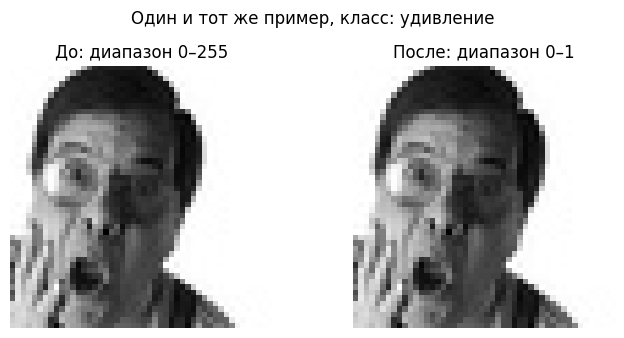

In [17]:
for name, original, prepared, labels in [
    ('train', X_train, X_train_prepared, y_train),
    ('validation', X_val, X_val_prepared, y_val),
    ('test', X_test, X_test_prepared, y_test)
]:
    assert prepared.shape == original.shape
    assert prepared.shape == (len(parts[name]), 48, 48)
    assert len(prepared) == len(labels)
    assert np.array_equal(labels, parts[name]['label'].to_numpy())
    assert np.isfinite(prepared).all()
    assert prepared.min() >= 0 and prepared.max() <= 1
    assert prepared.dtype == np.float32
    assert np.allclose(prepared, original / 255.0)
    print(name, ': проверено', len(prepared), 'изображений, тип', prepared.dtype)

fig, axes = plt.subplots(1, 2, figsize=(7, 3.4))
axes[0].imshow(X_train[0], cmap='gray', vmin=0, vmax=255)
axes[0].set_title('До: диапазон 0–255')
axes[1].imshow(X_train_prepared[0], cmap='gray', vmin=0, vmax=1)
axes[1].set_title('После: диапазон 0–1')
for ax in axes:
    ax.axis('off')
plt.suptitle(f'Один и тот же пример, класс: {EMOTION_RU[EMOTIONS[y_train[0]]]}')
plt.tight_layout()
plt.show()

**Вывод:** форма и порядок изображений сохранены; данные имеют тип `float32` и диапазон 0–1, метки не изменены, NaN и бесконечностей нет. Показан один и тот же пример: изменён только числовой масштаб. Размеры частей: 22 874 / 4 037 / 7 178. Основные ограничения: низкое разрешение, шум разметки и отсутствие ID людей. Подготовка выполнена; качество модели пока не оценивалось.

## 6. Результаты и выводы

### Сохранение

Сохраняем train, validation и test в формате NPZ (массив изображений, метки и ID; без сжатия — так сохранение быстрее), таблицы разделения, веса классов, соответствие меток и функцию обработки.

**Сохраняемые файлы** (папка `prepared_fer2013`): `train.npz`, `val.npz`, `test.npz` — изображения, метки и ID; `split_train.csv`, `split_val.csv`, `split_test.csv` — таблицы разделения (ID, путь, метка); `class_weights.json` — веса классов по train; `label_map.json` — коды эмоций и укрупнённые группы; `image_preprocessing.py` — функция нормализации; `split_description.txt` — описание разделения.

In [18]:
result_dir = Path('prepared_fer2013')
result_dir.mkdir(exist_ok=True)

datasets = [
    ('train', X_train_prepared, y_train, train_df),
    ('val', X_val_prepared, y_val, val_df),
    ('test', X_test_prepared, y_test, test_df)
]

for name, images, labels, part in datasets:
    np.savez(
        result_dir / f'{name}.npz',
        images=images,
        labels=labels,
        image_ids=part['image_id'].to_numpy(dtype=str)
    )
    part[['image_id', 'path', 'emotion', 'label']].to_csv(result_dir / f'split_{name}.csv', index=False)

(result_dir / 'class_weights.json').write_text(
    json.dumps({EMOTIONS[i]: float(class_weights[i]) for i in range(len(EMOTIONS))}, ensure_ascii=False, indent=2),
    encoding='utf-8')
(result_dir / 'label_map.json').write_text(
    json.dumps({'labels': {str(i): e for i, e in enumerate(EMOTIONS)}, 'groups': EMOTION_GROUP},
               ensure_ascii=False, indent=2), encoding='utf-8')

# getsource() получает текст функции, определённой выше в ноутбуке.
processing_code = 'import numpy as np\n\n' + getsource(normalize_images)
(result_dir / 'image_preprocessing.py').write_text(processing_code, encoding='utf-8')

description = f"""Описание разделения FER-2013
Исходно: {len(df)} изображений (официальные train/test).
После очистки: {len(df_clean)}.
Test: официальная часть, {len(test_df)} изображений, не изменялась.
Validation: 15 % официального train, стратификация по метке, random_state={RANDOM_STATE}.
Итог: train {len(train_df)}, validation {len(val_df)}, test {len(test_df)}.
Утечка: точные копии (по хешу пикселей) удалены из train; пересечений ID, путей и хешей между частями нет.
Ограничение: ID людей в наборе нет, связи между фотографиями одного человека не проверялись.
"""
(result_dir / 'split_description.txt').write_text(description, encoding='utf-8')
print(description)
print('Сохранено:', sorted(p.name for p in result_dir.iterdir()))

Описание разделения FER-2013
Исходно: 35887 изображений (официальные train/test).
После очистки: 34089.
Test: официальная часть, 7178 изображений, не изменялась.
Validation: 15 % официального train, стратификация по метке, random_state=42.
Итог: train 22874, validation 4037, test 7178.
Утечка: точные копии (по хешу пикселей) удалены из train; пересечений ID, путей и хешей между частями нет.
Ограничение: ID людей в наборе нет, связи между фотографиями одного человека не проверялись.

Сохранено: ['class_weights.json', 'image_preprocessing.py', 'label_map.json', 'split_description.txt', 'split_test.csv', 'split_train.csv', 'split_val.csv', 'test.npz', 'train.npz', 'val.npz']
